# 03 - Eye-in-Hand ChArUco 手眼标定

本 notebook 用于 RealSense 固定在机械臂末端、ChArUco 板固定在工作台上的 eye-in-hand 标定。

最终求解：

```text
T_gripper_camera
p_gripper = T_gripper_camera @ p_camera
```

每个样本必须包含同一静止时刻的：

- ChArUco RGB 图像；
- `T_base_gripper` 机器人末端位姿。

标定板在整个采集期间必须固定不动。建议采集 15–25 个具有明显旋转变化的姿态。

## Block 1：导入库、路径和参数

板参数必须与 02 使用的实体 ChArUco 板完全一致。机器人平移和所有输出统一使用米。

In [ ]:
from __future__ import annotations

import json
from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if not hasattr(cv2, "aruco"):
    raise ImportError("当前 OpenCV 没有 cv2.aruco；请安装 opencv-contrib-python。")

def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "cam_calibration").is_dir():
            return candidate
    raise RuntimeError("无法定位项目根目录；请从 Xinyu 项目内启动 Jupyter。")

PROJECT_ROOT = find_project_root()
CALIBRATION_ROOT = PROJECT_ROOT / "cam_calibration"
INPUT_DIR = CALIBRATION_ROOT / "inputs"
OUTPUT_ROOT = CALIBRATION_ROOT / "outputs"
SHARED_DIR = OUTPUT_ROOT / "shared"
CONFIG_DIR = CALIBRATION_ROOT / "config"
output_dir = OUTPUT_ROOT / "03_hand_eye"
for directory in (INPUT_DIR, OUTPUT_ROOT, SHARED_DIR, CONFIG_DIR, output_dir):
    directory.mkdir(parents=True, exist_ok=True)

intrinsics_path = SHARED_DIR / "camera_intrinsics.json"
robot_poses_path = output_dir / "robot_poses.csv"
result_path = CONFIG_DIR / "hand_eye_result.json"

dictionary_id = cv2.aruco.DICT_5X5_100
dictionary_name = "DICT_5X5_100"
squares_x, squares_y = 10, 7
square_length_m = 0.035
marker_length_m = 0.026

min_charuco_corners = 12
min_sample_count = 10
max_reprojection_error_px = 1.5
robot_translation_scale_to_m = 1.0

HAND_EYE_METHODS = {
    "TSAI": cv2.CALIB_HAND_EYE_TSAI,
    "PARK": cv2.CALIB_HAND_EYE_PARK,
    "HORAUD": cv2.CALIB_HAND_EYE_HORA来做UD,
    "ANDREFF": cv2.CALIB_HAND_EYE_ANDREFF,
    "DANIILIDIS": cv2.CALIB_HAND_EYE_DANIILIDIS,
}

print("Input poses:", robot_poses_path)
print("Intrinsics:", intrinsics_path)
print("Output:", result_path)

Input poses: /home/jingyun/Xinyu/ais_hiwi/cam_calibration/outputs/03_hand_eye/robot_poses.csv
Intrinsics: /home/jingyun/Xinyu/ais_hiwi/cam_calibration/outputs/shared/camera_intrinsics.json
Output: /home/jingyun/Xinyu/ais_hiwi/cam_calibration/config/hand_eye_result.json


## Block 2：齐次变换工具

统一采用 `T_A_B` 把 B 坐标系中的点变换到 A 坐标系。

In [2]:
def make_transform(rotation, translation):
    T = np.eye(4, dtype=np.float64)
    T[:3, :3] = np.asarray(rotation, dtype=np.float64).reshape(3, 3)
    T[:3, 3] = np.asarray(translation, dtype=np.float64).reshape(3)
    return T

def invert_transform(T):
    T = np.asarray(T, dtype=np.float64).reshape(4, 4)
    R, t = T[:3, :3], T[:3, 3]
    result = np.eye(4)
    result[:3, :3] = R.T
    result[:3, 3] = -R.T @ t
    return result

def validate_transform(T, name):
    T = np.asarray(T, dtype=np.float64)
    if T.shape != (4, 4) or not np.allclose(T[3], [0, 0, 0, 1], atol=1e-7):
        raise ValueError(f"{name} 不是合法 4x4 齐次矩阵。")
    R = T[:3, :3]
    if not np.allclose(R.T @ R, np.eye(3), atol=1e-3):
        raise ValueError(f"{name} 的旋转矩阵不正交。")
    if not np.isclose(np.linalg.det(R), 1.0, atol=1e-3):
        raise ValueError(f"{name} 的旋转矩阵行列式不为 1。")
    return T

def rotation_angle_deg(R):
    value = np.clip((np.trace(R) - 1.0) / 2.0, -1.0, 1.0)
    return float(np.degrees(np.arccos(value)))

def mean_rotation(rotations):
    matrix = np.sum(np.asarray(rotations), axis=0)
    U, _, Vt = np.linalg.svd(matrix)
    result = U @ Vt
    if np.linalg.det(result) < 0:
        U[:, -1] *= -1
        result = U @ Vt
    return result

## Block 3：加载 Color 内参

如果还没有共享内参，先运行下面的采集 cell。它直接读取 RealSense 当前
`640×480 @ 30 FPS` Color profile 的工厂内参并保存为 JSON，不需要运行 01/02。

In [36]:
CAPTURE_INTRINSICS_IF_MISSING = True
OVERWRITE_EXISTING_INTRINSICS = False
COLOR_WIDTH, COLOR_HEIGHT, COLOR_FPS = 640, 480, 30

def capture_realsense_color_intrinsics(output_path):
    import pyrealsense2 as rs

    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(
        rs.stream.color,
        COLOR_WIDTH,
        COLOR_HEIGHT,
        rs.format.bgr8,
        COLOR_FPS,
    )
    started = False
    try:
        profile = pipeline.start(config)
        started = True
        for _ in range(15):
            pipeline.wait_for_frames(5000)
        color_profile = profile.get_stream(
            rs.stream.color
        ).as_video_stream_profile()
        intr = color_profile.get_intrinsics()
        data = {
            "width": int(intr.width),
            "height": int(intr.height),
            "fx": float(intr.fx),
            "fy": float(intr.fy),
            "cx": float(intr.ppx),
            "cy": float(intr.ppy),
            "ppx": float(intr.ppx),
            "ppy": float(intr.ppy),
            "model": str(intr.model),
            "coeffs": [float(value) for value in intr.coeffs],
            "stream": "color",
            "resolution": [COLOR_WIDTH, COLOR_HEIGHT],
            "fps": COLOR_FPS,
            "serial_number": profile.get_device().get_info(
                rs.camera_info.serial_number
            ),
        }
        output_path.write_text(
            json.dumps(data, indent=2, ensure_ascii=False),
            encoding="utf-8",
        )
        return data
    finally:
        if started:
            pipeline.stop()

should_capture_intrinsics = (
    OVERWRITE_EXISTING_INTRINSICS
    or (CAPTURE_INTRINSICS_IF_MISSING and not intrinsics_path.exists())
)
if should_capture_intrinsics:
    captured_intrinsics = capture_realsense_color_intrinsics(intrinsics_path)
    print("已读取并保存 RealSense Color 内参:", intrinsics_path)
    print(json.dumps(captured_intrinsics, indent=2, ensure_ascii=False))
else:
    print("使用已有 Color 内参:", intrinsics_path)

使用已有 Color 内参: /home/jingyun/Xinyu/ais_hiwi/cam_calibration/outputs/shared/camera_intrinsics.json


## Block 4：加载并检查 Color 内参

内参分辨率必须与手眼标定图像一致。更换分辨率后需要重新读取。

In [ ]:
if not intrinsics_path.exists():
    raise FileNotFoundError(
        f"缺少 {intrinsics_path}；请先运行 01 或 02 获取 Color 内参。"
    )俄超噢
intrinsics = json.loads(intrinsics_path.read_text(encoding="utf-8"))
cx = intrinsics.get("cx", intrinsics.get("ppx"))
cy = intrinsics.get("cy", intrinsics.get("ppy"))
required = {"fx": intrinsics.get("fx"), "fy": intrinsics.get("fy"), "cx": cx, "cy": cy}
if any(value is None for value in required.values()):
    raise KeyError(f"相机内参字段不完整: {required}")

camera_matrix = np.array([
    [float(intrinsics["fx"]), 0.0, float(cx)],
    [0.0, float(intrinsics["fy"]), float(cy)],
    [0.0, 0.0, 1.0],
])
dist_coeffs = np.asarray(intrinsics.get("coeffs", [0, 0, 0, 0, 0]), dtype=np.float64)
expected_size = (int(intrinsics["width"]), int(intrinsics["height"]))
print("camera_matrix:\n", camera_matrix)
print("dist_coeffs:", dist_coeffs)
print("expected image size:", expected_size)

camera_matrix:
 [[605.37451172   0.         318.1541748 ]
 [  0.         604.33404541 255.36512756]
 [  0.           0.           1.        ]]
dist_coeffs: [0. 0. 0. 0. 0.]
expected image size: (640, 480)


## Block 5：创建 ChArUco 板和检测函数

`solvePnP` 输出 `T_camera_target`，即将标定板坐标变换到 Color optical frame。

In [5]:
aruco_dict = cv2.aruco.getPredefinedDictionary(dictionary_id)
try:
    board = cv2.aruco.CharucoBoard(
        (squares_x, squares_y), square_length_m, marker_length_m, aruco_dict
    )
except (AttributeError, TypeError):
    board = cv2.aruco.CharucoBoard_create(
        squares_x, squares_y, square_length_m, marker_length_m, aruco_dict
    )

try:
    board_corners_3d = np.asarray(board.getChessboardCorners(), dtype=np.float32)
except AttributeError:
    board_corners_3d = np.asarray(board.chessboardCorners, dtype=np.float32)

try:
    detector_params = cv2.aruco.DetectorParameters()
except AttributeError:
    detector_params = cv2.aruco.DetectorParameters_create()

if hasattr(cv2.aruco, "CharucoDetector"):
    charuco_detector = cv2.aruco.CharucoDetector(board)
else:
    charuco_detector = None

def estimate_target_pose(image_bgr):
    if (image_bgr.shape[1], image_bgr.shape[0]) != expected_size:
        raise ValueError(
            f"图像尺寸 {(image_bgr.shape[1], image_bgr.shape[0])} "
            f"与内参尺寸 {expected_size} 不一致。"
        )
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    if charuco_detector is not None:
        (
            charuco_corners,
            charuco_ids,
            marker_corners,
            marker_ids,
        ) = charuco_detector.detectBoard(gray)
    else:
        marker_corners, marker_ids, _ = cv2.aruco.detectMarkers(
            gray, aruco_dict, parameters=detector_params
        )
        charuco_corners, charuco_ids = None, None
        if marker_ids is not None:
            _, charuco_corners, charuco_ids = cv2.aruco.interpolateCornersCharuco(
                marker_corners, marker_ids, gray, board, camera_matrix, dist_coeffs
            )
    if marker_ids is None:
        return None
    if charuco_ids is None or len(charuco_ids) < min_charuco_corners:
        return None

    ids = charuco_ids.reshape(-1).astype(int)
    image_points = charuco_corners.reshape(-1, 2).astype(np.float32)
    object_points = board_corners_3d[ids].astype(np.float32)
    success, rvec, tvec = cv2.solvePnP(
        object_points, image_points, camera_matrix, dist_coeffs,
        flags=cv2.SOLVEPNP_ITERATIVE,
    )
    if not success:
        return None
    rotation, _ = cv2.Rodrigues(rvec)
    projected, _ = cv2.projectPoints(
        object_points, rvec, tvec, camera_matrix, dist_coeffs
    )
    reprojection_error = float(np.mean(np.linalg.norm(
        image_points - projected.reshape(-1, 2), axis=1
    )))
    return {
        "T_camera_target": make_transform(rotation, tvec),
        "corner_count": len(ids),
        "reprojection_error_px": reprojection_error,
        "charuco_corners": charuco_corners,
        "charuco_ids": charuco_ids,
        "marker_corners": marker_corners,
        "marker_ids": marker_ids,
    }

print("ChArUco corners:", len(board_corners_3d))

ChArUco corners: 54


## Block 6：机器人位姿和图像数据格式

读取 `inputs/robot_poses.csv`。每行格式为：

```text
sample_id,image_path,t00,...,t33
```

`image_path` 相对于项目根目录，矩阵是按行展开的 `T_base_gripper`。
Franka `O_T_EE` 通常为列主序，写入 CSV 前应先：

```python
T_base_gripper = np.asarray(O_T_EE).reshape(4, 4, order="F")
```

In [7]:
POSE_FIELDS = [f"t{r}{c}" for r in range(4) for c in range(4)]

if not robot_poses_path.exists():
    pd.DataFrame(
        columns=["sample_id", "image_path", *POSE_FIELDS]
    ).to_csv(robot_poses_path, index=False)

def save_hand_eye_sample(sample_id, T_base_gripper, warmup_frames=30):
    import pyrealsense2 as rs

    sample_id = str(sample_id)
    T = validate_transform(T_base_gripper, "T_base_gripper")
    image_dir = output_dir / "images"
    image_dir.mkdir(parents=True, exist_ok=True)
    image_path = image_dir / f"{sample_id}.png"

    if robot_poses_path.exists():
        existing = pd.read_csv(robot_poses_path, dtype={"sample_id": str})
        if not existing.empty and sample_id in set(existing["sample_id"]):
            raise ValueError(f"sample_id 已存在: {sample_id}")

    pipeline = rs.pipeline()
    config = rs.config()
    camera_serial = intrinsics.get("serial_number")
    if camera_serial:
        context = rs.context()
        connected_serials = [
            device.get_info(rs.camera_info.serial_number)
            for device in context.query_devices()
        ]
        if str(camera_serial) not in connected_serials:
            raise RuntimeError(
                f"内参 serial_number={camera_serial} 未连接。"
                f"当前可见 RealSense: {connected_serials}。"
                "请重新运行 Block 3/4 更新 camera_intrinsics.json，"
                "或关闭占用相机的程序。"
            )
        config.enable_device(str(camera_serial))
    config.enable_stream(
        rs.stream.color, expected_size[0], expected_size[1], rs.format.bgr8, 30
    )
    started = False
    try:
        pipeline.start(config)
        started = True
        color_frame = None
        for _ in range(max(1, int(warmup_frames))):
            color_frame = pipeline.wait_for_frames(5000).get_color_frame()
        if not color_frame:
            raise RuntimeError("没有获得 RealSense Color 帧。")
        image = np.asanyarray(color_frame.get_data())

        estimate = estimate_target_pose(image)
        if estimate is None:
            raise RuntimeError(
                "当前图像未检测到足够的 ChArUco 角点，样本未保存。"
            )
        if estimate["reprojection_error_px"] > max_reprojection_error_px:
            raise RuntimeError(
                f"当前重投影误差 {estimate['reprojection_error_px']:.3f}px "
                f"超过阈值 {max_reprojection_error_px:.3f}px，样本未保存。"
            )
        if not cv2.imwrite(str(image_path), image):
            raise IOError(f"图像保存失败: {image_path}")
    
    finally:
        if started:
            pipeline.stop()

    row = {
        "sample_id": sample_id,
        "image_path": str(image_path.relative_to(PROJECT_ROOT)),
    }
    row.update({
        field: float(value)
        for field, value in zip(POSE_FIELDS, T.reshape(-1))
    })
    pd.DataFrame([row]).to_csv(
        robot_poses_path,
        mode="a",
        header=not robot_poses_path.exists() or robot_poses_path.stat().st_size == 0,
        index=False,
    )
    print(
        "已保存样本:",
        sample_id,
        image_path,
        f"corners={estimate['corner_count']}",
        f"reprojection={estimate['reprojection_error_px']:.3f}px",
    )
    return image_path

def save_franka_o_t_ee_sample(sample_id, O_T_EE, warmup_frames=30):
    values = np.asarray(O_T_EE, dtype=np.float64)
    if values.size != 16:
        raise ValueError("Franka O_T_EE 必须包含 16 个数。")
    T_base_gripper = values.reshape(4, 4, order="F")
    return save_hand_eye_sample(
        sample_id,
        T_base_gripper,
        warmup_frames=warmup_frames,
    )

def save_tf2_matrix_sample(sample_id, tf2_matrix, warmup_frames=30):
    values = np.asarray(tf2_matrix, dtype=np.float64)
    if values.size != 16:
        raise ValueError("tf2 Matrix 必须包含 16 个数。")
    T_base_gripper = values.reshape(4, 4)
    return save_hand_eye_sample(
        sample_id,
        T_base_gripper,
        warmup_frames=warmup_frames,
    )

# 机械臂静止后示例：
# save_franka_o_t_ee_sample("0001", O_T_EE)
# 或从 `tf2_echo panda_link0 panda_hand` 复制 4x4 Matrix：
# save_tf2_matrix_sample("0001", tf2_matrix)
# 或者已有标准 4x4 矩阵时：
# save_hand_eye_sample("0001", T_base_gripper)

def load_pose_samples(path):
    if not path.exists():
        raise FileNotFoundError(path)
    table = pd.read_csv(path, dtype={"sample_id": str})
    if table.empty:
        raise RuntimeError(f"{path} 还是空模板。")
    missing = [name for name in ["sample_id", "image_path", *POSE_FIELDS] if name not in table]
    if missing:
        raise KeyError(f"robot_poses.csv 缺少字段: {missing}")
    if table["sample_id"].duplicated().any():
        duplicates = table.loc[table["sample_id"].duplicated(), "sample_id"].tolist()
        raise ValueError(f"sample_id 重复: {duplicates}")

    samples = []
    for index, row in table.iterrows():
        image_path = Path(str(row["image_path"]))
        if not image_path.is_absolute():
            image_path = PROJECT_ROOT / image_path
        values = [float(row[field]) for field in POSE_FIELDS]
        T = np.asarray(values, dtype=np.float64).reshape(4, 4)
        T[:3, 3] *= robot_translation_scale_to_m
        samples.append({
            "sample_id": str(row["sample_id"]),
            "image_path": image_path,
            "T_base_gripper": validate_transform(T, f"T_base_gripper[{index}]"),
        })
    return samples

existing_table = pd.read_csv(robot_poses_path, dtype={"sample_id": str})
print("采集函数已就绪。当前已保存样本数:", len(existing_table))
print(
    "机械臂停止后，先从机器人接口读取真实 T_base_gripper，"
    "再调用 save_hand_eye_sample(sample_id, T_base_gripper)。"
)


采集函数已就绪。当前已保存样本数: 3
机械臂停止后，先从机器人接口读取真实 T_base_gripper，再调用 save_hand_eye_sample(sample_id, T_base_gripper)。


### Block 6A：保存当前静止姿态样本

机械臂移动并完全静止后，更新 `sample_id` 和 `tf2_matrix`，再运行下面的 cell。它会拍摄当前 RGB 图像、检查 ChArUco，并将图像和机械臂位姿成对保存到 `cam_calibration/outputs/03_hand_eye`。

已保存样本: 0020 /home/jingyun/Xinyu/ais_hiwi/cam_calibration/outputs/03_hand_eye/images/0020.png corners=54 reprojection=0.597px


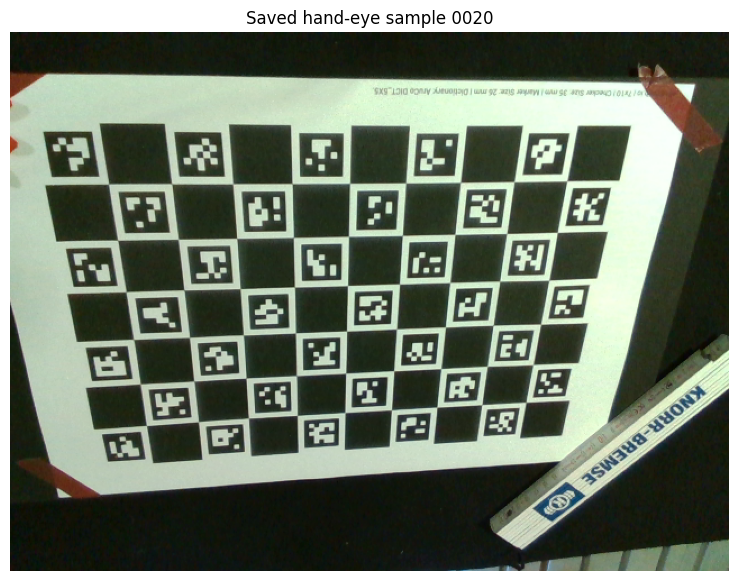

本次样本图像: /home/jingyun/Xinyu/ais_hiwi/cam_calibration/outputs/03_hand_eye/images/0020.png
位姿记录: /home/jingyun/Xinyu/ais_hiwi/cam_calibration/outputs/03_hand_eye/robot_poses.csv
采集输出目录: /home/jingyun/Xinyu/ais_hiwi/cam_calibration/outputs/03_hand_eye


In [25]:
# 每次采样必须使用新的编号，例如 "0001"、"0002"、...。


# 当前输入来自：
# ros2 run tf2_ros tf2_echo panda_link0 panda_hand -p 9
# 请复制输出中 Matrix 的四行，保持下面这种 4x4 行主序格式。
sample_id = "0020"

tf2_matrix = np.array([
    [-0.862910684, 0.016744401, -0.505078981, 0.599110777],
    [0.106366364, 0.983079729, -0.149132301, -0.010008496],
    [0.494035776, -0.182411271, -0.850091042, 0.492414416],
    [0.000000000, 0.000000000, 0.000000000, 1.000000000]
], dtype=np.float64)


if tf2_matrix.size != 16:
    raise ValueError(
        "请把 tf2_echo 输出的 4x4 Matrix 四行完整填入本 cell。"
    )

saved_image_path = save_tf2_matrix_sample(sample_id, tf2_matrix)
saved_image = cv2.imread(str(saved_image_path))
plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(saved_image, cv2.COLOR_BGR2RGB))
plt.title(f"Saved hand-eye sample {sample_id}")
plt.axis("off")
plt.show()
print("本次样本图像:", saved_image_path)
print("位姿记录:", robot_poses_path)
print("采集输出目录:", output_dir)

In [26]:

tf2_matrix = np.array([
    [0.846300247, 0.530547484, 0.047908859, 0.459237873],
    [0.530108423, -0.847631374, 0.022496952, 0.013727657],
    [0.052544754, 0.006357713, -0.998598332, 0.635687864],
    [0.000000000, 0.000000000, 0.000000000, 1.000000000]
], dtype=np.float64)

if tf2_matrix.size != 16:
    raise ValueError(
        "请把 tf2_echo 输出的 4x4 Matrix 四行完整填入本 cell。"
    )

saved_image_path = save_tf2_matrix_sample(sample_id, tf2_matrix)
saved_image = cv2.imread(str(saved_image_path))
plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(saved_image, cv2.COLOR_BGR2RGB))
plt.title(f"Saved hand-eye sample {sample_id}")
plt.axis("off")
plt.show()
print("本次样本图像:", saved_image_path)
print("位姿记录:", robot_poses_path)
print("采集输出目录:", output_dir)

ValueError: sample_id 已存在: 0020

## Block 7：检测所有样本并筛选

筛除图像缺失、ChArUco 角点不足或重投影误差过大的样本。

开始处理样本数: 20
0001 corners=54 reprojection=0.185px
0002 corners=54 reprojection=0.288px
0003 corners=54 reprojection=0.380px
0004 corners=51 reprojection=0.209px
0005 corners=50 reprojection=0.162px
0006 corners=54 reprojection=0.315px
0007 corners=54 reprojection=0.291px
0008 corners=54 reprojection=0.293px
0009 corners=54 reprojection=0.385px
0010 corners=52 reprojection=0.278px
0011 corners=54 reprojection=0.366px
0012 corners=54 reprojection=0.368px
0013 corners=54 reprojection=0.410px
0014 corners=50 reprojection=0.127px
0015 corners=48 reprojection=0.265px
0016 corners=54 reprojection=0.150px
0017 corners=54 reprojection=0.489px
0018 corners=54 reprojection=0.310px
0019 corners=54 reprojection=0.367px
0020 corners=54 reprojection=0.597px
有效样本: 20 拒绝样本: 0


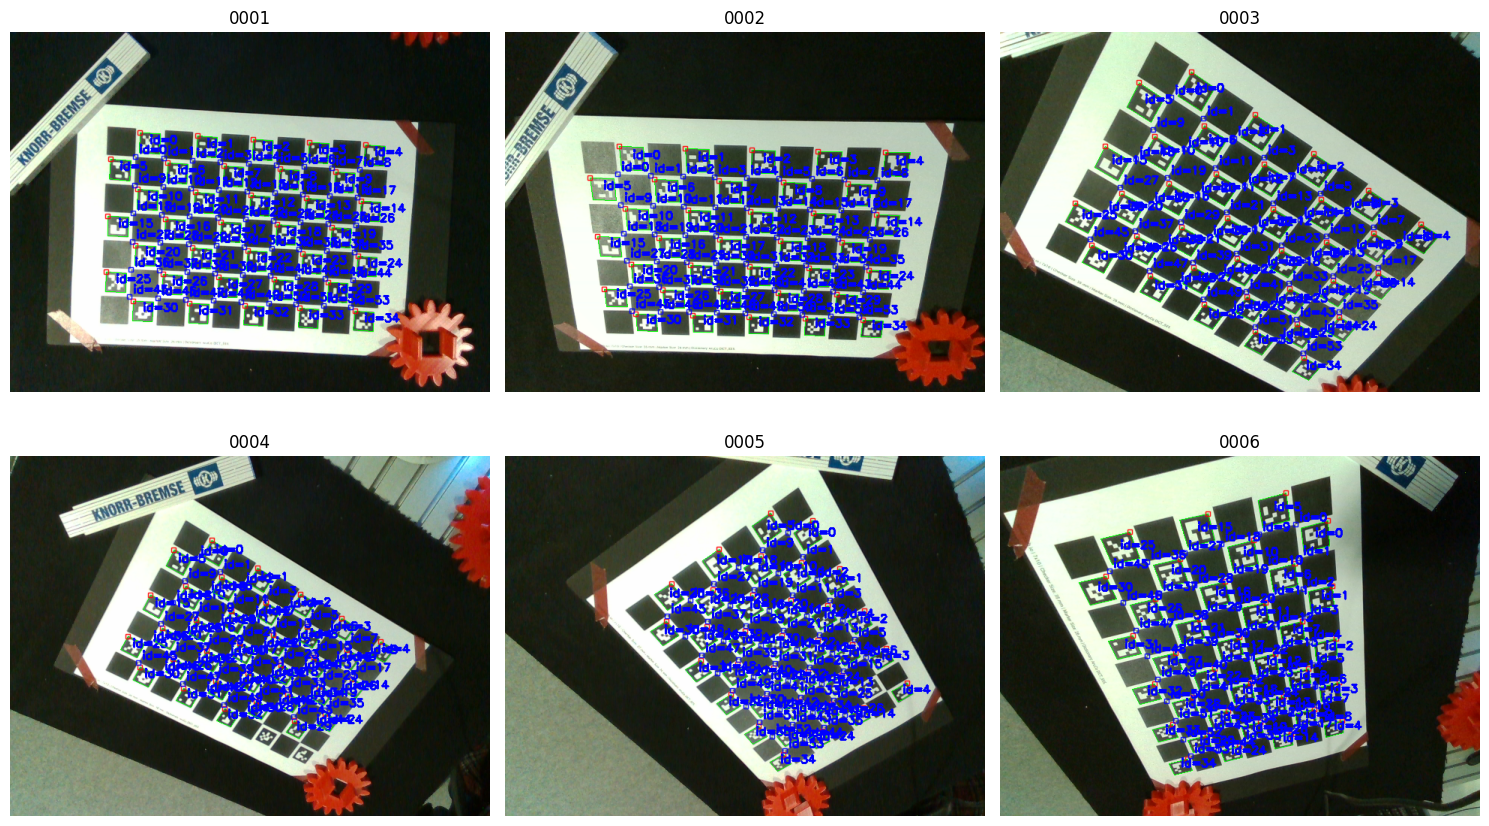

In [27]:
valid_samples, rejected_samples = [], []
preview_images = []

pose_samples = load_pose_samples(robot_poses_path)
print("开始处理样本数:", len(pose_samples))

for sample in pose_samples:
    image = cv2.imread(str(sample["image_path"]))
    if image is None:
        rejected_samples.append({**sample, "reason": "image not readable"})
        continue
    estimate = estimate_target_pose(image)
    if estimate is None:
        rejected_samples.append({**sample, "reason": "ChArUco not detected"})
        continue
    if estimate["reprojection_error_px"] > max_reprojection_error_px:
        rejected_samples.append({
            **sample, **estimate, "reason": "reprojection error too high"
        })
        continue
    valid_samples.append({**sample, **estimate})

    vis = image.copy()
    cv2.aruco.drawDetectedMarkers(
        vis, estimate["marker_corners"], estimate["marker_ids"]
    )
    cv2.aruco.drawDetectedCornersCharuco(
        vis, estimate["charuco_corners"], estimate["charuco_ids"]
    )
    preview_images.append((sample["sample_id"], vis))
    print(
        sample["sample_id"],
        f"corners={estimate['corner_count']}",
        f"reprojection={estimate['reprojection_error_px']:.3f}px",
    )

print("有效样本:", len(valid_samples), "拒绝样本:", len(rejected_samples))
if len(valid_samples) < min_sample_count:
    raise RuntimeError(
        f"有效样本只有 {len(valid_samples)} 个；建议至少 {min_sample_count} 个，实际使用 15–25 个。"
    )

if preview_images:
    count = min(6, len(preview_images))
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for axis, (sample_id, image) in zip(axes.flat, preview_images[:count]):
        axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        axis.set_title(sample_id)
        axis.axis("off")
    for axis in axes.flat[count:]:
        axis.axis("off")
    fig.tight_layout()
    fig.savefig(output_dir / "detected_samples.png", dpi=150)
    plt.show()

## Block 8：检查机器人姿态多样性

手眼标定必须包含充分的旋转变化。只有平移或姿态几乎平行会导致退化。

In [29]:
pairwise_rotation_deg = []
pairwise_translation_m = []
for i in range(len(valid_samples)):
    for j in range(i + 1, len(valid_samples)):
        relative = invert_transform(valid_samples[i]["T_base_gripper"]) @ valid_samples[j]["T_base_gripper"]
        pairwise_rotation_deg.append(rotation_angle_deg(relative[:3, :3]))
        pairwise_translation_m.append(np.linalg.norm(relative[:3, 3]))

pairwise_rotation_deg = np.asarray(pairwise_rotation_deg)
pairwise_translation_m = np.asarray(pairwise_translation_m)
print("机器人姿态两两旋转 [deg]: median/max =",
      np.median(pairwise_rotation_deg), np.max(pairwise_rotation_deg))
print("机器人姿态两两平移 [m]: median/max =",
      np.median(pairwise_translation_m), np.max(pairwise_translation_m))
if np.max(pairwise_rotation_deg) < 15:
    raise RuntimeError("机器人姿态旋转变化不足；请增加绕多个轴的倾斜姿态。")

机器人姿态两两旋转 [deg]: median/max = 75.82063467678775 179.1903604408533
机器人姿态两两平移 [m]: median/max = 0.34904673864085056 0.8091496701199999


## Block 9：执行多方法手眼标定

OpenCV 输入 `T_base_gripper` 和 `T_camera_target`，输出 camera → gripper 的
`T_gripper_camera`。

In [31]:
def solve_hand_eye(samples, method):
    rotations_gripper2base = [s["T_base_gripper"][:3, :3] for s in samples]
    translations_gripper2base = [s["T_base_gripper"][:3, 3] for s in samples]
    rotations_target2cam = [s["T_camera_target"][:3, :3] for s in samples]
    translations_target2cam = [s["T_camera_target"][:3, 3] for s in samples]
    R, t = cv2.calibrateHandEye(
        rotations_gripper2base,
        translations_gripper2base,
        rotations_target2cam,
        translations_target2cam,
        method=method,
    )
    return validate_transform(make_transform(R, t), "T_gripper_camera")

solutions = {}
for name, method in HAND_EYE_METHODS.items():
    try:
        solutions[name] = solve_hand_eye(valid_samples, method)
    except (cv2.error, ValueError) as error:
        print(f"{name} failed: {error}")
if not solutions:
    raise RuntimeError("所有手眼算法均失败。")
print("成功算法:", list(solutions))

成功算法: ['TSAI', 'PARK', 'HORAUD', 'ANDREFF', 'DANIILIDIS']


## Block 10：固定标定板一致性验证并选择算法

标定板固定时，每个样本计算出的

```text
T_base_target = T_base_gripper @ T_gripper_camera @ T_camera_target
```

应保持一致。使用平移与旋转 RMS 选择结果。

In [32]:
def evaluate_solution(samples, T_gripper_camera):
    base_target = [
        s["T_base_gripper"] @ T_gripper_camera @ s["T_camera_target"]
        for s in samples
    ]
    translations = np.asarray([T[:3, 3] for T in base_target])
    translation_mean = translations.mean(axis=0)
    translation_error = np.linalg.norm(translations - translation_mean, axis=1)
    rotation_mean = mean_rotation([T[:3, :3] for T in base_target])
    rotation_error = np.asarray([
        rotation_angle_deg(rotation_mean.T @ T[:3, :3]) for T in base_target
    ])
    return {
        "translation_rms_m": float(np.sqrt(np.mean(translation_error ** 2))),
        "translation_max_m": float(np.max(translation_error)),
        "rotation_rms_deg": float(np.sqrt(np.mean(rotation_error ** 2))),
        "rotation_max_deg": float(np.max(rotation_error)),
        "mean_T_base_target": make_transform(rotation_mean, translation_mean),
        "translation_errors_m": translation_error,
        "rotation_errors_deg": rotation_error,
    }

reports = {name: evaluate_solution(valid_samples, T) for name, T in solutions.items()}
report_table = pd.DataFrame({
    name: {
        "translation_rms_mm": report["translation_rms_m"] * 1000,
        "translation_max_mm": report["translation_max_m"] * 1000,
        "rotation_rms_deg": report["rotation_rms_deg"],
        "rotation_max_deg": report["rotation_max_deg"],
    }
    for name, report in reports.items()
}).T.sort_values(["translation_rms_mm", "rotation_rms_deg"])
display(report_table)

preferred_method = report_table.index[0]
T_gripper_camera = solutions[preferred_method]
selected_report = reports[preferred_method]
print("选择算法:", preferred_method)
print("T_gripper_camera:\n", T_gripper_camera)

,translation_rms_mm,translation_max_mm,rotation_rms_deg,rotation_max_deg
HORAUD,9.007098,14.249553,1.098108,2.348660
PARK,9.032136,13.970605,1.097329,2.345845
TSAI,9.501611,15.702315,1.107196,2.389831
DANIILIDIS,19.911767,42.511707,5.022660,8.911110
ANDREFF,26.282463,41.275608,1.098145,2.337876


选择算法: HORAUD
T_gripper_camera:
 [[-0.03897949  0.9991837  -0.01060771 -0.04735065]
 [-0.99916705 -0.03884616  0.0124976   0.0415954 ]
 [ 0.01207533  0.01108603  0.99986563  0.06209761]
 [ 0.          0.          0.          1.        ]]


## Block 11：残差可视化与物理合理性检查

标定结果的平移向量应与相机相对末端的实际安装距离大致一致。

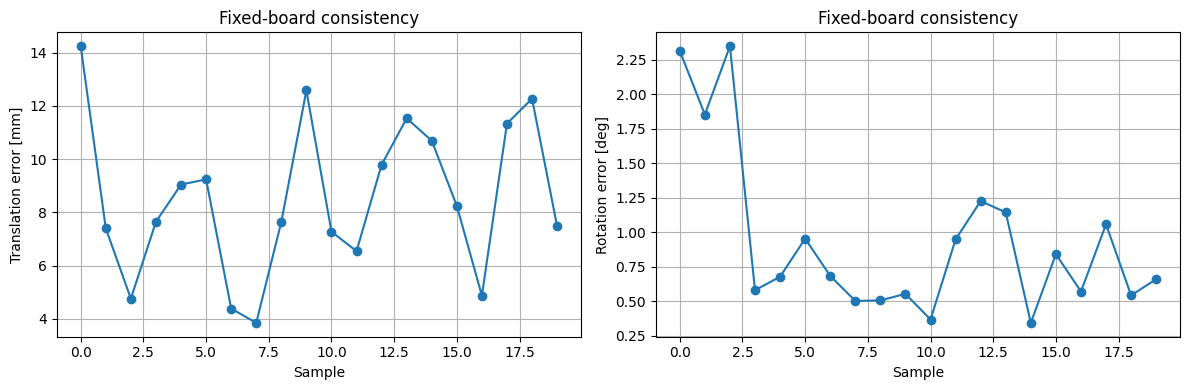

Camera origin relative to gripper: 88.5 mm


In [33]:
translation_errors_mm = selected_report["translation_errors_m"] * 1000
rotation_errors_deg = selected_report["rotation_errors_deg"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(translation_errors_mm, "o-")
axes[0].set(xlabel="Sample", ylabel="Translation error [mm]", title="Fixed-board consistency")
axes[1].plot(rotation_errors_deg, "o-")
axes[1].set(xlabel="Sample", ylabel="Rotation error [deg]", title="Fixed-board consistency")
for axis in axes:
    axis.grid(True)
fig.tight_layout()
fig.savefig(output_dir / "hand_eye_residuals.png", dpi=150)
plt.show()

mount_distance_m = float(np.linalg.norm(T_gripper_camera[:3, 3]))
print(f"Camera origin relative to gripper: {mount_distance_m*1000:.1f} mm")
if not 0.01 <= mount_distance_m <= 0.50:
    print("警告：平移量与常见机械安装距离不符，请检查单位和矩阵方向。")

## Block 12：保存结果

写入 `config/hand_eye_result.json`，供后续系统验证直接读取。

In [34]:
quality = {
    "translation_rms_m": selected_report["translation_rms_m"],
    "translation_max_m": selected_report["translation_max_m"],
    "rotation_rms_deg": selected_report["rotation_rms_deg"],
    "rotation_max_deg": selected_report["rotation_max_deg"],
}
result = {
    "status": "calibrated",
    "date_utc": datetime.now(timezone.utc).isoformat(),
    "method": preferred_method,
    "coordinate_convention": "p_gripper = T_gripper_camera @ p_camera",
    "T_gripper_camera": T_gripper_camera.tolist(),
    "translation_m": T_gripper_camera[:3, 3].tolist(),
    "rotation_matrix": T_gripper_camera[:3, :3].tolist(),
    "quality": quality,
    "valid_sample_ids": [s["sample_id"] for s in valid_samples],
    "rejected_samples": [
        {"sample_id": s["sample_id"], "reason": s["reason"]}
        for s in rejected_samples
    ],
    "board": {
        "dictionary_name": dictionary_name,
        "squares_x": squares_x,
        "squares_y": squares_y,
        "square_length_m": square_length_m,
        "marker_length_m": marker_length_m,
    },
    "camera_intrinsics": intrinsics,
}
result_path.write_text(json.dumps(result, indent=2, ensure_ascii=False), encoding="utf-8")
(output_dir / "hand_eye_result.json").write_text(
    json.dumps(result, indent=2, ensure_ascii=False), encoding="utf-8"
)
np.savez_compressed(
    output_dir / "hand_eye_result.npz",
    T_gripper_camera=T_gripper_camera,
    camera_matrix=camera_matrix,
    dist_coeffs=dist_coeffs,
)
report_table.to_csv(output_dir / "method_comparison.csv")
print("已保存:", result_path)

已保存: /home/jingyun/Xinyu/ais_hiwi/cam_calibration/config/hand_eye_result.json


## Block 13：结论提示

最终还应使用未参与标定的 3–5 个新姿态和 notebook 04 的工作台平面验证。

In [35]:
translation_rms_mm = quality["translation_rms_m"] * 1000
rotation_rms_deg = quality["rotation_rms_deg"]
if translation_rms_mm < 3.0 and rotation_rms_deg < 1.0:
    print("结论：固定板一致性较好，可以进入 04 系统级独立验证。")
else:
    print(
        f"结论：当前一致性为 {translation_rms_mm:.2f} mm / "
        f"{rotation_rms_deg:.3f} deg，建议增加姿态多样性、检查同步和板参数后重做。"
    )

结论：当前一致性为 9.01 mm / 1.098 deg，建议增加姿态多样性、检查同步和板参数后重做。
